# GB day-ahead price forecast: walkthrough

This notebook explains, step by step, how the hourly GB day-ahead price is forecast at **09:00 UK
time on D-1** for every hour of **delivery day D** (23:00 UK on D-1 to 23:00 UK on D), and how well it
works. It is written to be read top to bottom; every chart has a short "how to read it" note.

**To reproduce:** `python -m gb_da_forecast.collect` (download data, ~20 min), then
`python -m gb_da_forecast.backtest` (~25 min, writes `results/`), then run this notebook (~1 min;
it only reads `results/` and the collected data).

## Results in brief

Test year: **1 Nov 2025 to 10 Nov 2026** (375 delivery days). Every forecast was made as at 09:00 UK on D-1, models were retrained monthly, and every choice was made beforehand on the validation year (Nov 2024 to Oct 2025).

| Model | MAE (£/MWh) | vs naive | Battery capture |
|---|---|---|---|
| Naive: same hour yesterday | 20.79 | - | 79.0% |
| Lasso (price) | 14.41 | 31% better | 90.7% |
| Lasso (price / gas) | 12.87 | 38% better | 92.6% |
| Boosted trees (price) | 11.70 | 44% better | 92.8% |
| **Boosted trees (price / gas), the headline model** | **10.27** | **51% better** | 92.9% |
| Average of Lasso and trees | 10.69 | 49% better | 94.2% |

* The headline model, chosen on the validation year before the test year was touched, **halves the naive error**, and its advantage over every other model is statistically significant (Diebold-Mariano p < 0.05; p < 0.001 against all but the average).
* **Price / gas beats raw price** in both model families (trees £10.27 vs £11.70; Lasso £12.87 vs £14.41), as the merit-order economics suggested.
* For a 5 kW / 10 kWh home battery trading day-ahead only, scheduling on the learned models' forecasts earns about **£194-202 a year against £169** on the naive forecast, out of £214 possible with perfect foresight.
* The dominant input is the **forecast residual demand** (demand minus wind): the merit order in one number.

To forecast a new day: `python -m gb_da_forecast.forecast YYYY-MM-DD` (after refreshing the data with `collect`).

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gb_da_forecast import plots
from gb_da_forecast.config import REPO_ROOT
from gb_da_forecast.features import FEATURE_GROUPS, build_dataset

warnings.filterwarnings("ignore")
plots.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
RESULTS = REPO_ROOT / "results"
run_info = json.loads((RESULTS / "run_info.json").read_text())
df = build_dataset()
print(f"{len(df):,} delivery hours, delivery days {df['delivery_day'].min()} to {df['delivery_day'].max()}")

45,049 delivery hours, delivery days 2021-09-21 to 2026-11-10


## 1. The question

At 09:00 on D-1 we must forecast all 23-25 hourly prices of delivery day D, 20 minutes before the
EPEX 60-minute auction (DA1) closes at 09:20. The first hour of D starts 14 hours after the forecast,
the last one 37 hours after.

| When (example: D = Wed 11 Nov) | What happens |
|---|---|
| Mon, 09:20 / 09:50 | EPEX DA1 / N2EX auctions for delivery day Tue (prices of D-1 become known) |
| **Tue, 09:00** | **Forecast made for Wed** (the cutoff) |
| Tue, 09:20 / 09:50 | Auctions for Wed close |
| Tue 23:00 to Wed 23:00 | Delivery |

**Target.** Historical EPEX DA1 prices are not openly available, so the target is the **N2EX** GB
hourly day-ahead price (Nord Pool's auction for the same product and delivery hours, closing 30
minutes later), published free by NESO. Swapping in EPEX data only changes the loader.

## 2. The data and the economics behind it

Power prices follow the **merit order**: plants are lined up from cheapest to run (wind, solar,
nuclear) to most expensive (old gas "peakers"), and the price each hour is set by the most expensive
plant needed. Two things therefore drive the price:

* **how far up the stack we go**: demand minus wind and solar (*residual demand*);
* **how expensive the gas part of the stack is**: the gas price.

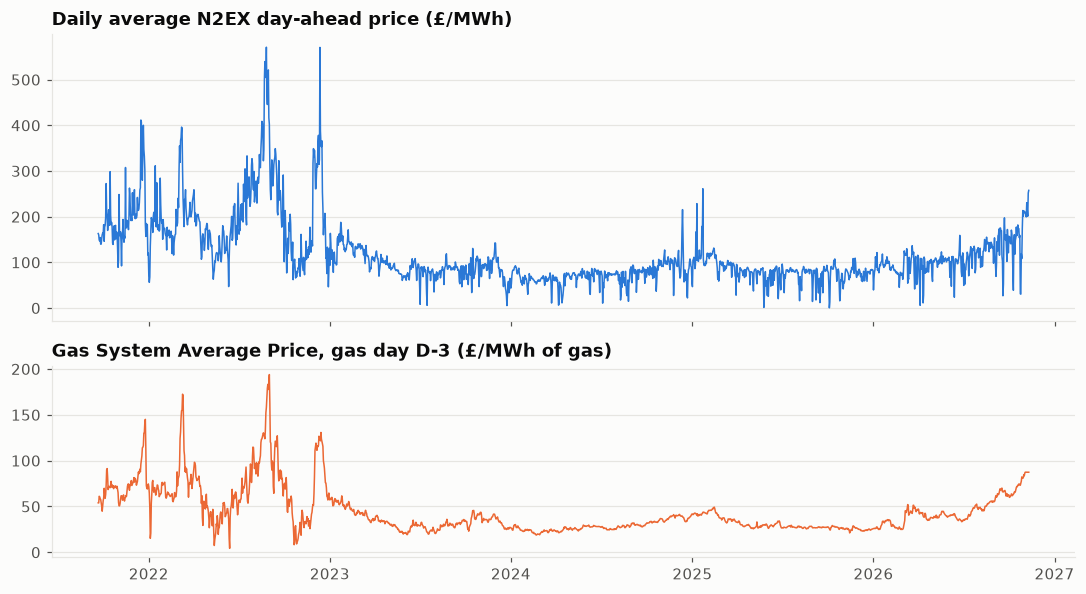

In [2]:
plots.price_and_gas(df);

**How to read it.** Top: the daily average power price; bottom: the gas price the model uses
(gas day D-3, the latest value certainly published by the cutoff). The two move together: the 2022
energy crisis, the calm 2023-2025, and the climb in late 2026 all show up in both.

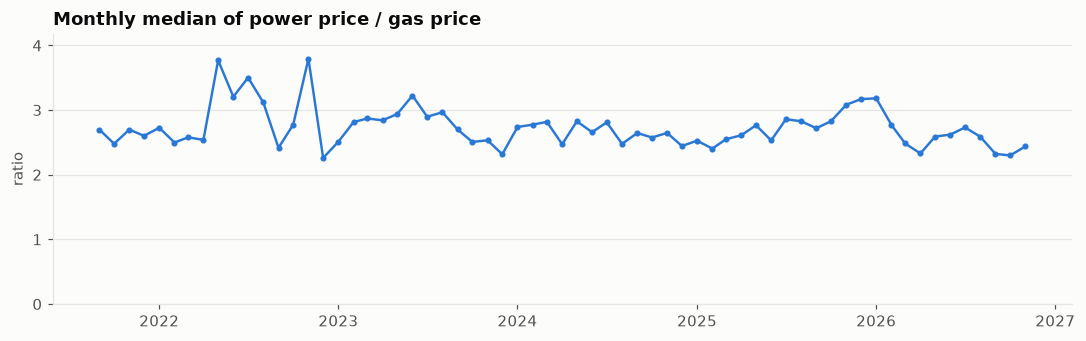

In [3]:
plots.ratio_over_time(df);

**How to read it.** Each point is the median, over a month, of *power price ÷ gas price*. While the
price level moved between ~£70 and ~£200/MWh, this ratio stayed around 2.3-3.2. It is the market's
**implied heat rate**: roughly how many units of gas the price-setting plant burns per unit of power,
plus carbon. The spikes in 2022 are months when the GB gas price briefly collapsed (an LNG glut), so
the ratio's denominator was tiny.

This stability is why the models also try predicting **price ÷ gas** and multiplying back: the model
then learns something stable (which plant sets the price at each hour) instead of having to cope
with price levels it has never seen. The idea follows the structural "bid stack" view of power prices
(Coulon & Howison 2009) and the econometric result that, in a gas-dominated market, the gas
coefficient is the plants' heat rate (Ghelasi & Ziel 2024); the implied market heat rate is also a
standard industry metric (e.g. CPUC 2019).

**Why this ratio and not something else?**

| Option | Verdict |
|---|---|
| Raw price | The baseline form. Fine for a linear model (a gas weight scales it); trees struggle when the price level moves |
| Spark spread (price - h x gas) | Additive: needs a fixed heat rate h, and does not let the peak premium grow with gas |
| Log price | Compresses spikes and is multiplicative, but impossible with zero or negative prices (591 negative hours here) |
| asinh(price) | Handles negatives and spikes (Uniejewski, Weron & Ziel 2018), but on its own does not remove gas-driven level shifts |
| Price ÷ recent average price | Purely statistical: reacts to level changes from any cause, but always lags them |
| **Price ÷ gas** | Economically motivated (implied heat rate), stable across regimes, handles negative prices (the ratio just goes negative) |

Two details: the ratio divides by the **7-day mean** gas price (gas days D-9 to D-3), because the
single-day price occasionally collapses (to £4/MWh in June 2022); and errors in the ratio are
multiplied back by the gas price, so they grow when gas is expensive, which is realistic. Both the raw
and the ratio forms are run, and the validation year decides.

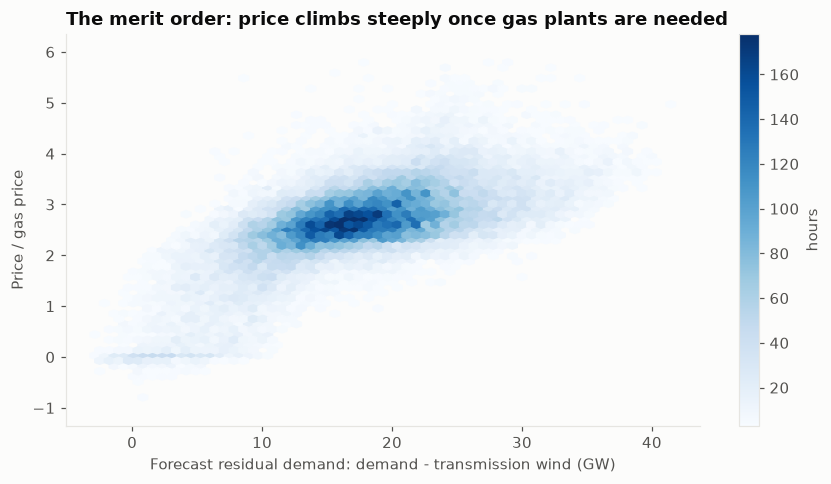

In [4]:
plots.merit_order(df);

**How to read it.** Every hour since Sept 2021 is a point (darker = more hours). Horizontal axis:
forecast residual demand (national demand minus transmission wind, as known at the cutoff). Vertical:
price ÷ gas. Below ~5 GW the ratio sits near zero (wind and nuclear set the price, sometimes negative);
from ~10 GW gas plants set it and the ratio is 2-3; at very high residual demand older, less
efficient plants are needed and it climbs to 4+. This **hockey stick** is the non-linear shape a
straight-line model cannot follow but decision trees can.

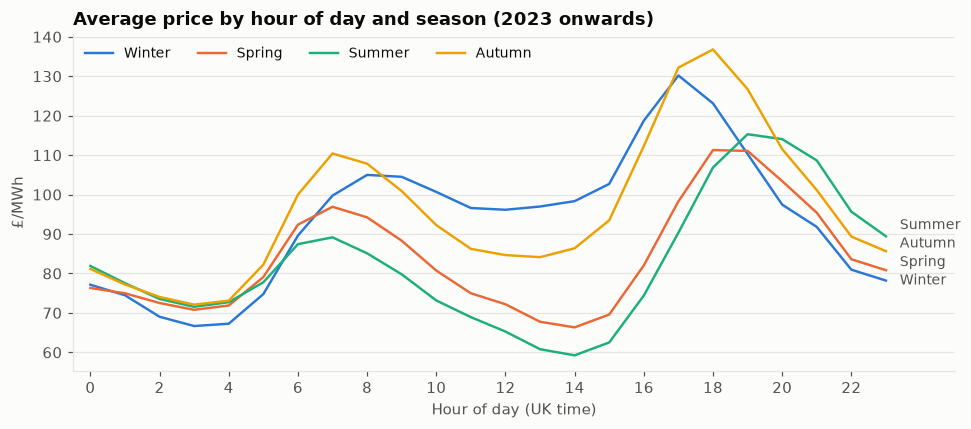

In [5]:
plots.daily_shape_by_season(df);

**How to read it.** The average price at each hour of the day, by season, since 2023. Morning and
evening peaks follow demand; the midday dip in spring and summer is solar. This is why the hour of day
and the solar forecast are inputs.

## 3. Inputs: what is known at 09:00 on D-1

Each row of the modelling table is one delivery hour. Every input is something that had been
published by the cutoff:

| Group | Inputs | Why |
|---|---|---|
| Calendar | hour, day of week, bank holiday, month, smooth day-of-year | daily and weekly patterns |
| Fundamentals | demand, transmission wind, embedded solar and wind forecasts for that hour; residual demand and its daily mean/min/max | how far up the merit order each hour goes |
| Gas | gas price of gas day D-3, its 7-day mean | cost of the price-setting plant |
| Price lags | same hour on delivery days D-1, D-2, D-7; D-1's mean, min, max and last hour | persistence; captures what we cannot see (outages, interconnector conditions) |
| Optional context | continental prices of D-1, imbalance prices and generation mix of the last 24 h | kept only if they help on the validation year |

**Point-in-time ("as-of") rule.** Forecast publishers re-issue forecasts many times a day (each
edition is a *vintage*). For each half hour of D we take the latest value published by 09:00 on D-1
(`asof.as_of_cutoff`). Not "the latest vintage": Elexon's demand forecast has a half-hourly vintage
that only reaches ~05:00 tomorrow and a separate 08:45 release for 05:00-05:00, so the two are
stitched per period. Residual demand is demand minus *transmission* wind only: NESO's national
demand is measured on the transmission network, so embedded solar and wind already reduce it.

In [6]:
day = df[df["delivery_day"] == pd.Timestamp("2026-07-15").date()]
cols = ["start_utc", "hour", "price", "p_d1", "p_d7", "demand_fc", "wind_fc", "emb_solar_fc", "residual_fc", "gas_sap"]
day[cols].head(8)

,start_utc,hour,price,p_d1,p_d7,demand_fc,wind_fc,emb_solar_fc,residual_fc,gas_sap
42192,2026-07-14 22:00:00+00:00,23,126.82,118.42,110.51,"24,305.00","6,549.00",0.00,"17,756.00",40.15
42193,2026-07-14 23:00:00+00:00,0,123.04,112.70,104.90,"22,582.50","5,966.00",0.00,"16,616.50",40.15
42194,2026-07-15 00:00:00+00:00,1,117.00,109.31,100.38,"21,883.00","5,519.00",0.00,"16,364.00",40.15
42195,2026-07-15 01:00:00+00:00,2,113.86,108.25,95.94,"20,946.00","5,240.00",0.00,"15,706.00",40.15
42196,2026-07-15 02:00:00+00:00,3,113.20,107.62,94.68,"20,439.50","5,065.00",0.00,"15,374.50",40.15
42197,2026-07-15 03:00:00+00:00,4,118.26,110.79,92.52,"19,899.00","4,932.00",4.50,"14,967.00",40.15
42198,2026-07-15 04:00:00+00:00,5,127.69,113.48,97.17,"20,259.50","4,771.00",226.00,"15,488.50",40.15
42199,2026-07-15 05:00:00+00:00,6,136.00,121.60,114.68,"21,756.50","4,550.00","1,426.00","17,206.50",40.15


**How to read it.** The first eight hours of delivery day 15 July 2026 (note it starts at 22:00 UTC =
23:00 BST on 14 July). `price` is the target; everything to its right was known at 09:00 BST on 14 July.

## 4. The models: a ladder from simple to flexible

Each rung must beat the one below it to justify its complexity.

1. **Naive baselines** (no learning): same hour yesterday; same hour last week; yesterday scaled by
   the change in gas. Surprisingly hard to beat, and the bar every model is measured against
   (Lago et al. 2021).
2. **Lasso regression**: price = weighted sum of inputs, one model per hour of the day. The Lasso
   penalty sets the weights of useless inputs to exactly zero, so it selects inputs itself. Fully
   readable. A simplified version of the field's "LEAR" benchmark (Ziel & Weron 2018; Lago et al.
   2021), which also transforms prices and uses all 24 hourly prices of several past days.
   Weakness: straight lines only.
3. **Gradient-boosted decision trees**: hundreds of small if-then trees, each correcting the previous
   ones' errors. Learns bends (the hockey stick) and interactions automatically and copes with missing
   inputs. The strongest practical family on tabular data (M5 competition, Makridakis et al. 2022;
   Grinsztajn et al. 2022). Weakness: cannot extrapolate beyond the range it was trained on, which
   the price ÷ gas target addresses.
4. **Average of Lasso and trees**: combining forecasts often beats each one.

Each learned model comes in two target forms: **price** (£/MWh) and **price ÷ gas** (with all
money-valued inputs also divided by gas, so the model works in "units of gas").

Neural networks, ARIMA and pre-trained foundation models were considered and not used: too little
data for neural networks to pay off (~45,000 hourly rows), poor use of outside drivers for
ARIMA-type models, and opacity for all of them (see README).

## 5. How it is tested: a walk-forward backtest

The backtest replays history as if the forecaster had been running live:

| Period | Used for | Retraining |
|---|---|---|
| Sept 2021 - Oct 2024 | training only | - |
| **Validation year**: Nov 2024 - Oct 2025 | every choice: which optional inputs, tree settings, headline model | every 3 months |
| **Test year**: Nov 2025 - latest day | the final, untouched evaluation, choices frozen | every month |

For every forecast month, the model is trained only on delivery days before that month. Making the
choices on the validation year and touching the test year once keeps the test results honest: tuning
on the test year would be another form of looking ahead.

In [7]:
groups = pd.read_csv(RESULTS / "validation_input_groups.csv").pivot(index="inputs", columns="target", values="MAE")
print("Validation-year MAE (£/MWh) of boosted trees with each set of input groups:")
groups.sort_values("ratio")

Validation-year MAE (£/MWh) of boosted trees with each set of input groups:


target,ratio,raw
inputs,,
base+all,9.22,9.24
base+continental,9.29,9.47
base+gen_mix,9.40,9.43
base,9.56,9.85
base+imbalance,9.79,9.87


**What this shows.** Each row is a set of inputs; each column a target form; each cell the validation-year MAE of the boosted trees. Continental prices and the generation mix each helped on their own; imbalance prices on their own made the error worse (ratio form: £9.79 vs £9.56 for the base set); all three together gave the lowest error for both target forms (£9.22 ratio, £9.24 raw), so all were kept. Only these five combinations were tried: continental + generation mix *without* imbalance was not, and is the obvious simplification to test next. The price / gas form beat the raw form in every row.

In [8]:
tuning = pd.read_csv(RESULTS / "validation_gbm_tuning.csv")
print("Boosted-tree settings tried on the validation year (best 5 per target):")
tuning.sort_values("MAE").groupby("target").head(5).sort_values(["target", "MAE"])

Boosted-tree settings tried on the validation year (best 5 per target):


,target,loss,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE
9,ratio,absolute_error,0.05,600,63,40,9.12
13,ratio,squared_error,0.05,600,63,40,9.12
12,ratio,squared_error,0.05,600,15,40,9.20
11,ratio,absolute_error,0.10,300,63,40,9.22
15,ratio,squared_error,0.10,300,63,40,9.23
3,raw,absolute_error,0.10,300,63,40,9.44
1,raw,absolute_error,0.05,600,63,40,9.46
0,raw,absolute_error,0.05,600,15,40,9.47
2,raw,absolute_error,0.10,300,15,40,9.69
5,raw,squared_error,0.05,600,63,40,9.76


**Settings, in plain words.** `loss`: what the trees minimise, absolute errors (robust to spikes) or
squared errors. `learning_rate` and `max_iter`: how much each new tree corrects, and how many trees.
`max_leaf_nodes`: how many if-then rules per tree. `min_samples_leaf`: no rule may rest on fewer than
40 hours of data.

In [9]:
valid = pd.read_csv(RESULTS / "validation_models.csv", index_col=0)
print("Validation year, all models (MAE, RMSE, bias in £/MWh; rMAE relative to 'same hour yesterday'):")
valid.sort_values("MAE")

Validation year, all models (MAE, RMSE, bias in £/MWh; rMAE relative to 'same hour yesterday'):


,MAE,RMSE,bias,rMAE
gbm_ratio,9.12,20.32,-0.88,0.48
gbm_raw,9.44,19.42,-1.02,0.49
average,10.02,21.18,-0.31,0.52
lasso_ratio,12.44,23.51,0.26,0.65
lasso_raw,13.93,24.00,1.14,0.73
naive_d1,19.15,36.37,0.11,1.00
naive_d1_gas,19.31,36.49,0.13,1.01
naive_d7,24.45,43.55,0.88,1.28


In [10]:
print("Choices frozen for the test year:")
print(json.dumps(run_info["choices"], indent=2))

Choices frozen for the test year:
{
  "groups_raw": [
    "calendar",
    "fundamentals",
    "gas",
    "price_lags",
    "continental",
    "imbalance",
    "gen_mix"
  ],
  "groups_ratio": [
    "calendar",
    "fundamentals",
    "gas",
    "price_lags",
    "continental",
    "imbalance",
    "gen_mix"
  ],
  "gbm_params_raw": {
    "loss": "absolute_error",
    "learning_rate": 0.1,
    "max_iter": 300,
    "max_leaf_nodes": 63,
    "min_samples_leaf": 40
  },
  "gbm_params_ratio": {
    "loss": "absolute_error",
    "learning_rate": 0.05,
    "max_iter": 600,
    "max_leaf_nodes": 63,
    "min_samples_leaf": 40
  },
  "best_lasso": "lasso_ratio",
  "best_gbm": "gbm_ratio",
  "headline": "gbm_ratio"
}


**What was chosen, and why.** All input groups; trees with up to 63 rules each and absolute-error loss (learning rate 0.05 and 600 trees for the ratio form; 0.1 and 300 for the raw form). The best Lasso and the best trees were both the **price / gas** versions, and the headline model is the **boosted trees on price / gas** (validation MAE £9.12 against £19.16 for naive, 52% better). How much each choice mattered on the validation year: tree settings moved the MAE by up to £0.32 (ratio form) or £0.98 (raw form); input groups by up to about £0.6; the target form by £0.33 (best raw £9.44 vs best ratio £9.12). So settings, inputs and target form all mattered by similar, modest amounts. The best settings sit at the edge of the small grid (the largest trees), so slightly larger models might help a little.

## 6. Test-year results

**How to read the metrics.** **MAE**: on average, how far each hourly forecast is from the actual price
(£/MWh). **RMSE**: like MAE but punishes big misses more; RMSE much larger than MAE means a few spikes
dominate. **bias**: average of forecast minus actual (positive = too high). **rMAE**: MAE divided by the
naive "same hour yesterday" MAE; 0.70 = 30% better than naive.

In [11]:
test = pd.read_parquet(RESULTS / "test_predictions.parquet")
metrics_table = pd.read_csv(RESULTS / "test_metrics.csv", index_col=0)
print(f"Test year: {run_info['test_period'][0]} to {run_info['test_period'][1]}, {test['delivery_day'].nunique()} delivery days")
metrics_table.sort_values("MAE")

Test year: 2025-11-01 to 2026-11-10, 375 delivery days


,MAE,RMSE,bias,rMAE
gbm_ratio,10.27,15.59,-2.18,0.49
average,10.69,15.71,-0.86,0.51
gbm_raw,11.70,17.41,-1.82,0.56
lasso_ratio,12.87,18.57,0.46,0.62
lasso_raw,14.41,20.61,0.69,0.69
naive_d1,20.79,33.94,-0.55,1.00
naive_d1_gas,21.19,34.22,0.00,1.02
naive_d7,27.41,42.89,-3.17,1.32


**Reading the table.** The headline model's forecasts are on average £10.27/MWh from the actual hourly price, half the naive error. RMSE (£15.6) is about 1.5 times its MAE, against 1.6 times for the naive forecast: big misses still exist, but they matter less. The bias of about -£2.2 means the trees forecast slightly too low on average, and this happens in 10 of the 13 months, so it is not only the autumn 2026 price rise. About a quarter of it comes from spikes: on the 5% most expensive hours the error is £18.1 and the forecast is £11.3 too low on average. **Spikes are under-predicted**, typical of models that minimise average error; a simple correction for recent bias is an obvious improvement to try. The test MAE (£10.3) is higher than on the validation year (£9.1) because 2026 prices were higher and more volatile (mean £111/MWh), and errors grow with the price level.

In [12]:
dm = pd.read_csv(RESULTS / "test_diebold_mariano.csv")
dm["verdict"] = np.where(dm["p_value"] < 0.05, np.where(dm["dm_stat"] < 0, "A better (significant)", "B better (significant)"), "no significant difference")
dm

,model_a,model_b,dm_stat,p_value,verdict
0,gbm_ratio,naive_d1,-8.31,0.00,A better (significant)
1,gbm_ratio,naive_d7,-8.35,0.00,A better (significant)
2,gbm_ratio,naive_d1_gas,-8.66,0.00,A better (significant)
3,gbm_ratio,lasso_raw,-9.22,0.00,A better (significant)
4,gbm_ratio,lasso_ratio,-6.19,0.00,A better (significant)
5,gbm_ratio,gbm_raw,-5.34,0.00,A better (significant)
6,gbm_ratio,average,-2.12,0.03,A better (significant)


**How to read it.** The Diebold-Mariano test asks whether the difference in error between the headline
model (A) and each other model (B) is larger than chance. It compares daily average errors and allows
for the fact that consecutive days' errors are related. p < 0.05: the difference is unlikely to be luck.

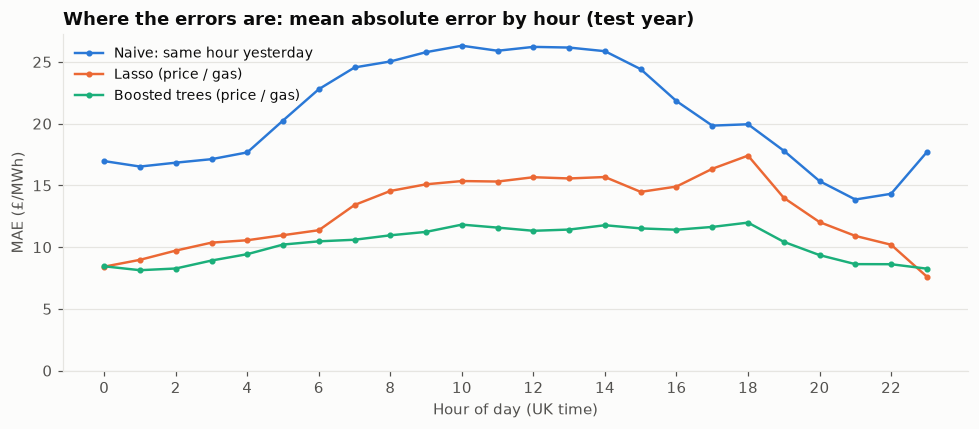

In [13]:
by_hour = pd.read_csv(RESULTS / "test_mae_by_hour.csv", index_col=0)
show = ["naive_d1", run_info["choices"]["best_lasso"], run_info["choices"]["best_gbm"]]
plots.mae_by_hour(by_hour, show);

**How to read it.** The naive forecast is worst in the daytime (08:00-15:00, about £25), because yesterday's sun and wind are a poor guide to today's. The models are flatter: the hardest hours are still midday (solar uncertainty) and the 17:00-18:00 evening peak (tight supply, spikes). The Lasso keeps up with the trees overnight but falls behind during the day, where the price relationships bend most.

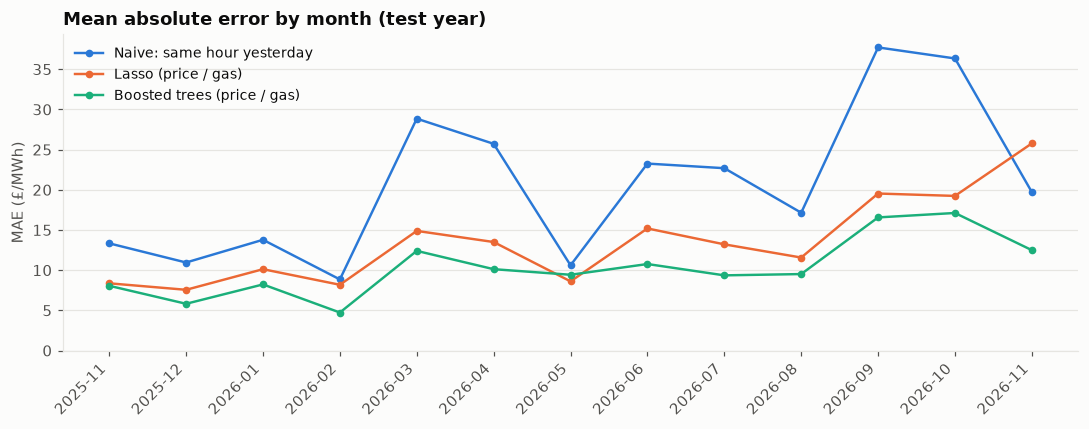

In [14]:
by_month = pd.read_csv(RESULTS / "test_mae_by_month.csv", index_col=0)
plots.mae_by_month(by_month, show);

**How to read it.** The boosted trees beat the naive forecast in every month; the Lasso did not always (the price / gas Lasso is worse than naive in November 2026, and the raw Lasso in December 2025 and February 2026). Errors rise in March-April and September-October 2026: windy, volatile shoulder seasons and, in autumn, a fast-rising gas price. November 2026 covers only 10 days, and its last six use a gas price up to nine days old, because the free ONS gas series is published with a lag (a live system would read National Gas directly). Both price / gas models multiply by the gas price, so a stale gas price hurts them; the Lasso visibly so.

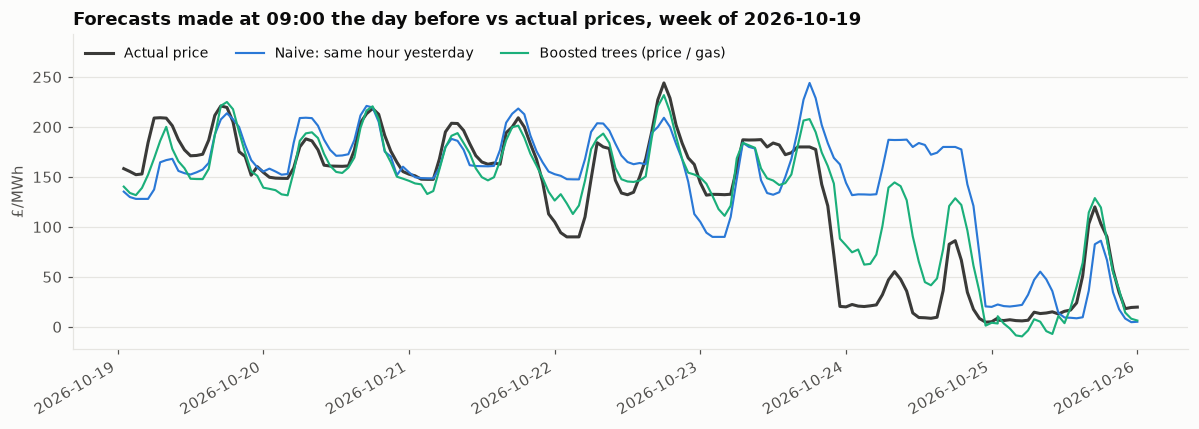

In [15]:
plots.sample_week(test, ["naive_d1", run_info["choices"]["headline"]], start="2026-10-19");

**How to read it.** 19-25 October 2026, a typical week: the model's error is 48% below the naive forecast's, close to the test-year median week (46%). Black is the actual price, blue the naive forecast (yesterday's prices) and green the model, each made at 09:00 the day before. Monday to Friday the model tracks the daily shape and the evening peaks. On Saturday 24 October prices collapsed to about £10-50 as the wind picked up. The naive forecast repeated Friday's £130-190; the model, reading the wind forecast, predicted a fall but not its full depth (£60-90 overnight, about £140 in the morning against £50 actual). The remaining error is weather and market uncertainty that the information available at 09:00 on Friday did not resolve.

## 7. Battery value: is the forecast useful for decisions?

Capture uses price forecasts to decide **when to charge and discharge batteries**, and the money
depends on picking the right cheap and expensive hours, which MAE does not measure. A forecast with the
right daily *shape* but the wrong level (say, every hour 20% too high) has a large MAE yet produces
exactly the perfect schedule; a forecast with a lower MAE that puts the evening peak an hour late
discharges at the wrong time. (A constant £ offset, unlike a percentage one, can change the schedule
slightly, because with efficiency losses the battery sells less energy than it buys.)

**Method, for each test day:** (1) plan the profit-maximising schedule of a 5 kW / 10 kWh home battery
(90% round-trip efficiency, at most one cycle a day, empty at the start and end of the day) *as if the
forecast were right*, by solving a small linear program; (2) settle that schedule at the actual prices;
(3) plan again on the actual prices (perfect foresight, the most that was possible). **Capture rate** =
realised profit ÷ perfect-foresight profit over the test year.

**Worked example** (no losses, 1 MW / 2 MWh): actual prices £40 and £45 at 03:00-04:00, £150, £140,
£100 at 18:00-20:00. Perfect foresight buys at 03-04 and sells at 18-19: profit £205. A forecast that
thinks the peak is 19-20 sells at £140 + £100: profit £155, a **76%** capture rate.

Simplifications: day-ahead market only (no intraday or imbalance re-trading), no household load or
solar, no degradation cost, hourly resolution, the battery does not move prices. It measures how useful
a forecast is for decisions; it is not a revenue estimate.

,capture rate (%),£ per battery per year
naive_d1,79.04,169.18
naive_d7,79.81,170.84
naive_d1_gas,79.04,169.18
lasso_raw,90.72,194.19
lasso_ratio,92.60,198.22
gbm_raw,92.76,198.56
gbm_ratio,92.88,198.80
average,94.24,201.71
perfect foresight,100.00,214.05


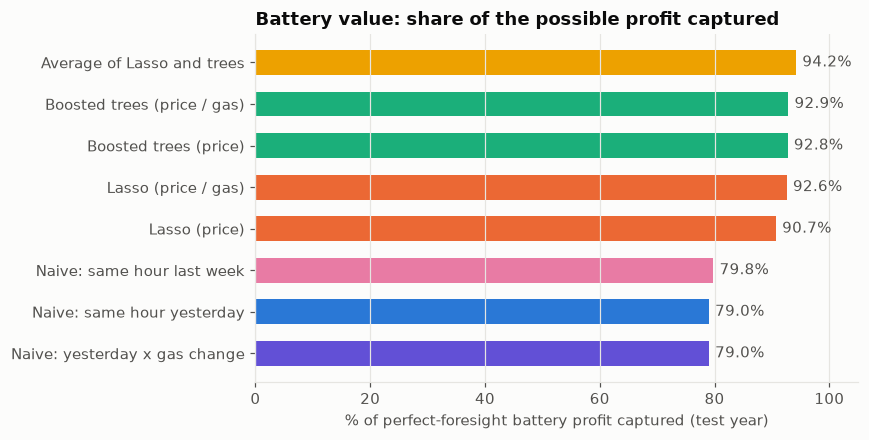

In [16]:
battery = pd.read_csv(RESULTS / "battery_summary.csv", index_col=0)
order = battery.drop(index="perfect foresight").sort_values("capture_rate", ascending=False).index.tolist()
plots.battery_capture(battery, order);
battery.assign(capture_rate=lambda t: t["capture_rate"] * 100).rename(
    columns={"capture_rate": "capture rate (%)", "profit_gbp_per_year": "£ per battery per year"})

**How to read it.** All learned models capture 91-94% of the perfect-foresight profit, against 79-80% for the naive forecasts. For one 5 kW / 10 kWh battery trading day-ahead only, that is about £194-202 a year against £169 for naive, out of £214 possible: roughly **£25-33 more per battery per year** from better forecasts, which across a fleet of thousands of batteries adds up. The ranking differs from MAE: the average of Lasso and trees captures the most (94.2%) although the trees alone have the lowest MAE, because it gets the order of cheap and expensive hours right slightly more often. The 'same hour last week' naive forecast beats 'same hour yesterday' here despite a much worse MAE (£27.4 vs £20.8). And 'yesterday x gas change' captures exactly the same 79.0% as 'yesterday': multiplying a whole day by one number changes the level but not which hours are cheap or dear, so the battery schedule is identical. Level accuracy and shape accuracy are different things, which is why this measure exists.

## 8. What the models learned

**Permutation importance** (boosted trees): shuffle one input at random across the test year and
measure how much the MAE gets worse. A big increase means the model relies on that input; zero means
it could do without it. Error bars show the spread over five shuffles.

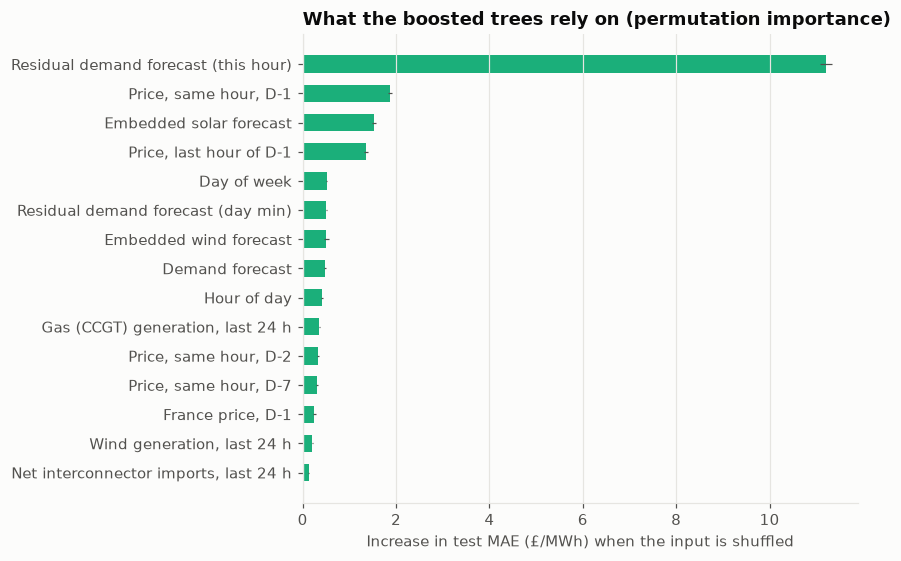

In [17]:
imp = pd.read_csv(RESULTS / "gbm_permutation_importance.csv")
plots.importance(imp);

**How to read it.** Forecast residual demand dominates: shuffling it raises the test MAE by about £11/MWh, more than all other inputs combined. That is the merit order. Next come yesterday's price at the same hour and in its last hour, and the embedded solar forecast (the midday dip). The gas price scores low because in the price / gas model the gas level is divided out of the target and multiplied back afterwards: it does its work outside the trees. Imbalance prices barely matter, consistent with the input-group comparison.

In [18]:
coefs = pd.read_csv(RESULTS / "lasso_coefficients.csv", index_col=0)
hour18 = coefs["18"].loc[lambda s: s.abs() > 0].sort_values(key=abs, ascending=False)
print(f"Lasso ({run_info['choices']['best_lasso']}), 18:00 model: {len(hour18)} of {len(coefs)} inputs kept")
hour18.head(12).to_frame("weight per standard deviation")

Lasso (lasso_ratio), 18:00 model: 12 of 39 inputs kept


,weight per standard deviation
residual_fc,0.25
wind_fc,-0.16
cont_fr_d1,0.16
cont_be_d1,0.15
p_d1,0.13
emb_wind_fc,-0.05
p_d7,0.05
p_d2,0.03
cont_no2_d1,0.02
gas_ref,-0.01


**How to read it.** For numeric inputs, each weight is the change in the prediction (here in units of the gas price) for a one standard-deviation increase in that input, holding the others fixed; for the day-of-week indicators (`dow_1` to `dow_6`) it is the difference from Monday. Inputs not listed were set to exactly zero by the Lasso penalty (the 18:00 model keeps 12 of 39; across all hours the median model keeps 20). At 18:00 the largest weights are residual demand (+), the wind forecast (-), the previous day's French and Belgian prices (+) and yesterday's 18:00 price (+). The signs make economic sense: more residual demand means a higher price, more wind a lower one, and a pricier continent means GB imports less power, which raises the GB price.

## 9. Limitations and next steps

* **Target proxy.** N2EX stands in for EPEX DA1. The method transfers unchanged; the price gap between the two auctions is unmeasured without EPEX data.
* **Gas data.** The free ONS series lags about a week (the last test days used a stale gas price; the forecast command warns when this happens). A live system should read National Gas directly, and the forward-looking day-ahead gas price would be better than the realised SAP if available.
* **Missing drivers.** No carbon price (GOV.UK fortnightly auction prices could be added) and no EUR/GBP rate for the continental prices. Weather enters only through NESO and Elexon forecasts; Open-Meteo's Previous Runs API (2024 onwards) could add temperature honestly.
* **Spikes and bias.** The most expensive hours are under-predicted and the trees are about £2 too low on average. A correction for recent bias, or a probabilistic version (the same trees with a quantile loss) giving the battery optimiser ranges rather than single numbers, are natural next steps.
* **Choices.** Five input-group combinations and a small grid of tree settings were tried; the best settings sit at the grid's edge, and continental + generation mix without imbalance was not tried. Monthly retraining, no recency weighting.
* **Imbalance data.** Elexon's API serves the latest settlement run, so before 2024 the feature uses imbalance prices ~1 hour old at the cutoff and from 2024 ~25 hours old; in August-September 2025 some periods were only re-published months later and are therefore unavailable to the model for those days.
* **Next steps.** The same pipeline forecasts DA2 (half-hourly, 15:30) and intraday prices with a later cutoff; and a model of the imbalance price and system direction would let the optimiser treat imbalance as a fourth market.

## References

1. Lago, Marcjasz, De Schutter & Weron (2021), *Forecasting day-ahead electricity prices: A review of
   state-of-the-art algorithms, best practices and an open-access benchmark*, Applied Energy 293, 116983.
2. Ziel & Weron (2018), *Day-ahead electricity price forecasting with high-dimensional structures:
   Univariate vs. multivariate modeling frameworks*, Energy Economics 70, 396-420.
3. Weron (2014), *Electricity price forecasting: A review of the state-of-the-art with a look into the
   future*, International Journal of Forecasting 30(4), 1030-1081.
4. Makridakis, Spiliotis & Assimakopoulos (2022), *M5 accuracy competition: Results, findings, and
   conclusions*, International Journal of Forecasting 38(4), 1346-1364.
5. Grinsztajn, Oyallon & Varoquaux (2022), *Why do tree-based models still outperform deep learning on
   typical tabular data?*, NeurIPS Datasets and Benchmarks. arXiv:2207.08815.
6. Coulon & Howison (2009), *Stochastic behaviour of the electricity bid stack: from fundamental drivers
   to power prices*, Journal of Energy Markets.
7. Ghelasi & Ziel (2024), *From day-ahead to mid and long-term horizons with econometric electricity
   price forecasting models*, arXiv:2406.00326.
8. California Public Utilities Commission (2019), *Implied Market Heat Rate and Electric Cost
   Overcharge in 2018*.
9. Uniejewski, Weron & Ziel (2018), *Variance stabilizing transformations for electricity spot price
   forecasting*, IEEE Transactions on Power Systems.
10. Diebold & Mariano (1995), *Comparing predictive accuracy*, Journal of Business & Economic Statistics 13(3), 253-263.